# Stoichiometry walkthrough

Worked examples using `stoichkit`: formula parsing, equation balancing, limiting reagents, empirical formulas, and a comparison of fuel CO$_2$ intensity.

In [1]:
import sys
sys.path.insert(0, "..")
import matplotlib.pyplot as plt
import stoichkit as sk

## 1. Formulas and molar masses

In [2]:
for f in ["H2O", "Ca(OH)2", "Al2(SO4)3", "K4[Fe(CN)6]", "CuSO4·5H2O", "C6H12O6"]:
    print(f"{f:14s} {sk.molar_mass(f):9.3f} g/mol   {dict(sk.parse_formula(f))}")

H2O               18.015 g/mol   {'H': 2, 'O': 1}
Ca(OH)2           74.092 g/mol   {'Ca': 1, 'O': 2, 'H': 2}
Al2(SO4)3        342.132 g/mol   {'Al': 2, 'S': 3, 'O': 12}
K4[Fe(CN)6]      368.345 g/mol   {'K': 4, 'Fe': 1, 'C': 6, 'N': 6}
CuSO4·5H2O       249.677 g/mol   {'Cu': 1, 'S': 1, 'O': 9, 'H': 10}
C6H12O6          180.156 g/mol   {'C': 6, 'H': 12, 'O': 6}


## 2. Balancing equations

The coefficients come from the integer null space of the element-composition matrix, computed with exact fractions.

In [3]:
for eq in [
    "C3H8 + O2 -> CO2 + H2O",
    "KMnO4 + HCl -> KCl + MnCl2 + H2O + Cl2",
    "Ca3(PO4)2 + SiO2 + C -> CaSiO3 + P4 + CO",
    "Cu + HNO3 -> Cu(NO3)2 + NO + H2O",
]:
    print(sk.balance(eq))

C3H8 + 5O2 -> 3CO2 + 4H2O
2KMnO4 + 16HCl -> 2KCl + 2MnCl2 + 8H2O + 5Cl2
2Ca3(PO4)2 + 6SiO2 + 10C -> 6CaSiO3 + P4 + 10CO
3Cu + 8HNO3 -> 3Cu(NO3)2 + 2NO + 4H2O


## 3. Limiting reagent: thermite

100 g of Fe$_2$O$_3$ reacts with 30 g of Al.

In [4]:
rxn = sk.balance("Fe2O3 + Al -> Al2O3 + Fe")
res = sk.limiting_reagent(rxn, {"Fe2O3": 100.0, "Al": 30.0})
print(rxn)
print("limiting reagent :", res["limiting"])
print("reaction extent  : %.4f mol" % res["extent_mol"])
for p, g in res["theoretical_yield_g"].items():
    print(f"theoretical {p:6s}: {g:.2f} g")
for s, g in res["excess_g"].items():
    print(f"excess {s:6s}     : {g:.2f} g")

Fe2O3 + 2Al -> Al2O3 + 2Fe
limiting reagent : Al
reaction extent  : 0.5559 mol
theoretical Al2O3 : 56.68 g
theoretical Fe    : 62.09 g
excess Fe2O3      : 11.23 g


## 4. Empirical formula from combustion analysis

A compound is 54.53 % C, 9.15 % H and 36.32 % O by mass.

In [5]:
emp = sk.empirical_formula({"C": 54.53, "H": 9.15, "O": 36.32})
print("empirical formula:", emp, f"({sk.molar_mass(emp):.2f} g/mol)")

empirical formula: C2H4O (44.05 g/mol)


## 5. CO$_2$ produced per kilogram of fuel

Each hydrocarbon is assumed to burn completely to CO$_2$ and H$_2$O.

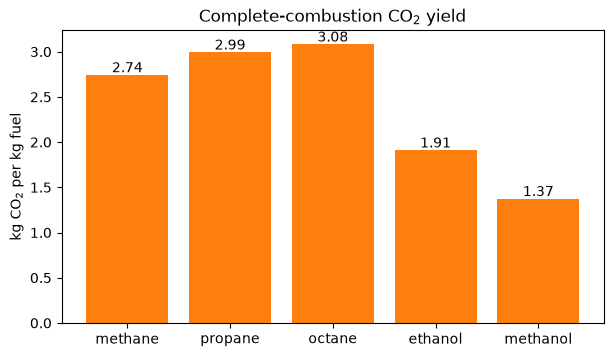

In [6]:
fuels = {"methane": "CH4", "propane": "C3H8", "octane": "C8H18", "ethanol": "C2H6O", "methanol": "CH4O"}
co2_per_kg = {}
for name, f in fuels.items():
    r = sk.balance(f"{f} + O2 -> CO2 + H2O")
    co2_per_kg[name] = r.coefficient("CO2") * sk.molar_mass("CO2") / (r.coefficient(f) * sk.molar_mass(f))

plt.figure(figsize=(7, 3.8))
plt.bar(co2_per_kg.keys(), co2_per_kg.values(), color="C1")
plt.ylabel("kg CO$_2$ per kg fuel"); plt.title("Complete-combustion CO$_2$ yield")
for i, v in enumerate(co2_per_kg.values()):
    plt.text(i, v + 0.03, f"{v:.2f}", ha="center")
plt.show()

## 6. Elemental composition of glucose

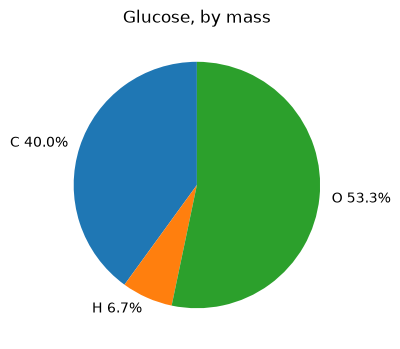

In [7]:
fr = sk.mass_fractions("C6H12O6")
plt.figure(figsize=(4, 4))
plt.pie(fr.values(), labels=[f"{k} {v*100:.1f}%" for k, v in fr.items()], startangle=90)
plt.title("Glucose, by mass")
plt.show()